In [ ]:
import os
import random
import inspect

import torch
import torch.nn as nn
from blitz.modules import BayesianLinear
import pickle
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer, TVAESynthesizer
from sdv.evaluation.single_table import evaluate_quality, run_diagnostic

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

from pathlib import Path
from IPython.display import display, Markdown

GLOBAL_SEED = 123

In [ ]:
def set_all_seeds(seed=GLOBAL_SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


set_all_seeds(GLOBAL_SEED)
print(f"GLOBAL_SEED = {GLOBAL_SEED}")


In [44]:
class BNN(nn.Module):
    def __init__(self,n_features,n_outputs,M):
        super().__init__()
        self.fc1 = BayesianLinear(n_features,M)
        self.fc2 = BayesianLinear(M,M)
        self.fc3 = BayesianLinear(M,n_outputs)
        self.relu = nn.ReLU()    

    def forward(self,x):
        x = self.relu(self.fc1(x)) 
        x = self.relu(self.fc2(x))
        return self.fc3(x)
    
    def kl_loss(self):
        kl = 0
        for layer in [self.fc1, self.fc2, self.fc3]:
            mu = layer.weight_sampler.mu
            rho = layer.weight_sampler.rho
            sigma = torch.log1p(torch.exp(rho))
            kl_w = 0.5*(mu**2 + sigma**2 - torch.log(sigma**2)-1).sum()
            
            mu_b = layer.bias_sampler.mu
            rho_b = layer.bias_sampler.rho
            sigma_b = torch.log1p(torch.exp(rho_b))  # = log(1+exp(rho))
            kl_b = 0.5*(mu_b**2 + sigma_b**2 - torch.log(sigma_b**2)-1).sum()  
            
            kl += kl_w + kl_b
        return kl

In [45]:
class MLP_MC(nn.Module):
    def __init__(self, n_features, n_outputs, M, drop_rate = 0.2):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(n_features, M),
            nn.ReLU(),
            nn.Dropout(drop_rate),
            nn.Linear(M, M),
            nn.ReLU(),
            nn.Dropout(drop_rate),
            nn.Linear(M, n_outputs)
        )
        
    def forward(self, x):
        return self.model(x)
    
    # keep Dropout active at evaluation time
    def drop_enable(self):
        for m in self.modules():
            if isinstance(m, nn.Dropout):
                m.train()

In [46]:
import pickle

with open('model_final_bnn.pkl', 'rb') as f:
    bnn_model = pickle.load(f)
with open('model_final_mlp_drop.pkl', 'rb') as f:
    mlp_model = pickle.load(f)
with open('balanced_data.pkl', 'rb') as b:
    data = pickle.load(b)

X_bal=data['X_bal']
y_bal=data['y_bal']

with open('model_final_bnn.pkl', 'rb') as f:
    bnn_model = pickle.load(f)

In [47]:
data = X_bal.copy()

metadata = SingleTableMetadata()
metadata.detect_from_dataframe(data)

scaler = MinMaxScaler()
scaler.fit(data)

feature_cols = list(data.columns)

In [ ]:
def synthesizer_kwargs(cls, **kwargs):
    params = inspect.signature(cls.__init__).parameters
    if "cuda" in params:
        kwargs.setdefault("cuda", False)
    return kwargs


set_all_seeds(GLOBAL_SEED)
ctgan_model = CTGANSynthesizer(
    metadata,
    **synthesizer_kwargs(
        CTGANSynthesizer,
        epochs=300,
        verbose=True,
        enforce_min_max_values=False,
    ),
)
# 300 epochs because it consistently gives the best results without overfitting.
# enforce_min_max_values=False so the data is not forced into the same range.

set_all_seeds(GLOBAL_SEED + 1)
tvae_model = TVAESynthesizer(
    metadata,
    **synthesizer_kwargs(
        TVAESynthesizer,
        epochs=300,
        enforce_min_max_values=False,
    ),
)


In [49]:
print("ctgan model ongoing...")
set_all_seeds(GLOBAL_SEED)
ctgan_model.fit(data)

print("tvae model ongoing...")
set_all_seeds(GLOBAL_SEED + 1)
tvae_model.fit(data)


ctgan model ongoing...


Gen. (-04.47) | Discrim. (+00.18): 100%|██████████| 300/300 [07:34<00:00,  1.51s/it]


tvae model ongoing...


In [50]:
sample_size = [500, 1000, 2000, 5000]
synthetic_ctgan = {}
synthetic_tvae = {}

for i in sample_size:
    print(f"Generation of {i} new values")
    set_all_seeds(GLOBAL_SEED + 1000 + i)
    synthetic_ctgan[i] = ctgan_model.sample(num_rows=i)

    set_all_seeds(GLOBAL_SEED + 2000 + i)
    synthetic_tvae[i] = tvae_model.sample(num_rows=i)

print("Done")


Generation of 500 new values
Generation of 1000 new values
Generation of 2000 new values
Generation of 5000 new values
Done


In [51]:
quality_scores = {}
column_shapes = {}

for i in sample_size:
    report_ctgan = evaluate_quality(real_data=data, synthetic_data=synthetic_ctgan[i], metadata=metadata, verbose=False)
    report_tvae = evaluate_quality(real_data=data, synthetic_data=synthetic_tvae[i], metadata=metadata, verbose=False)

    quality_scores[i] = {
        'ctgan_quality': report_ctgan.get_score(),
        'tvae_quality': report_tvae.get_score()
    }
    column_shapes[i] = {
        'ctgan': report_ctgan.get_details(property_name='Column Shapes'),
        'tvae': report_tvae.get_details(property_name='Column Shapes')
    }

quality_df = pd.DataFrame(quality_scores).T
print(quality_df)

      ctgan_quality  tvae_quality
500        0.808605      0.855938
1000       0.816738      0.861005
2000       0.811677      0.855096
5000       0.815856      0.861291


In [ ]:
def c2st_score(real_df, synthetic_df, cv=5, max_iter=2000):
    """
    Classifier Two-Sample Test.
    AUC ~ 0.5  -> real and synthetic are indistinguishable (good sign)
    AUC ~ 1.0  -> the classifier tells them apart easily (bad sign)
    """
    combined = pd.concat([real_df, synthetic_df], ignore_index=True)
    labels = np.array([0] * len(real_df) + [1] * len(synthetic_df))

    c2st_scaler = StandardScaler()
    combined_scaled = c2st_scaler.fit_transform(combined)

    clf = LogisticRegression(max_iter=max_iter, solver='lbfgs')
    scores = cross_val_score(clf, combined_scaled, labels, cv=cv, scoring='roc_auc')
    return scores.mean(), scores.std()


def hellinger_distance(real_col, synth_col, bins=50):
    """
    Hellinger distance between the distributions (discretized into histograms) of a column.
    0 = identical distributions, 1 = completely disjoint supports.
    """
    combined_min = min(real_col.min(), synth_col.min())
    combined_max = max(real_col.max(), synth_col.max())
    bin_edges = np.linspace(combined_min, combined_max, bins + 1)

    p_hist, _ = np.histogram(real_col, bins=bin_edges)
    q_hist, _ = np.histogram(synth_col, bins=bin_edges)

    p = p_hist / p_hist.sum()
    q = q_hist / q_hist.sum()

    return np.sqrt(np.sum((np.sqrt(p) - np.sqrt(q)) ** 2)) / np.sqrt(2)


def hellinger_score(real_df, synth_df, bins=50):
    """
    Mean Hellinger distance over all numeric columns, plus the per-column detail.
    Lower mean = more similar distributions (consistent with the definition, to be read the opposite
    way from quality_score/ks_complement, where higher = better).
    """
    per_col = {
        col: hellinger_distance(real_df[col].values, synth_df[col].values, bins=bins)
        for col in real_df.columns
    }
    per_col_series = pd.Series(per_col, name='hellinger_distance')
    return per_col_series.mean(), per_col_series


diagnostics_summary = []
column_shapes_full = {}
hellinger_details_full = {}

for synth_name, synth_dict in [('CTGAN', synthetic_ctgan), ('TVAE', synthetic_tvae)]:
    for n in sample_size:
        synth = synth_dict[n]

        report = evaluate_quality(real_data=data, synthetic_data=synth, metadata=metadata, verbose=False)
        shapes_df = report.get_details(property_name='Column Shapes')
        ks_complement = shapes_df.loc[shapes_df['Metric'] == 'KSComplement', 'Score'].mean()

        auc_c2st, auc_std = c2st_score(data, synth)

        hellinger_mean, hellinger_per_col = hellinger_score(data, synth)

        column_shapes_full[(synth_name, n)] = shapes_df
        hellinger_details_full[(synth_name, n)] = hellinger_per_col

        diagnostics_summary.append({
            'model': synth_name,
            'n_samples': n,
            'quality_score': report.get_score(),
            'ks_complement': ks_complement,
            'c2st_auc': auc_c2st,
            'c2st_std': auc_std,
            'hellinger_mean': hellinger_mean
        })

df_diagnostics = pd.DataFrame(diagnostics_summary).sort_values(['model', 'n_samples']).reset_index(drop=True)
print(df_diagnostics)

   model  n_samples  quality_score  ks_complement  c2st_auc  c2st_std  \
0  CTGAN        500       0.808605       0.675904  0.784119  0.030037   
1  CTGAN       1000       0.816738       0.671104  0.793200  0.026387   
2  CTGAN       2000       0.811677       0.677825  0.783921  0.022444   
3  CTGAN       5000       0.815856       0.677143  0.795895  0.019526   
4   TVAE        500       0.855938       0.727087  0.787609  0.031560   
5   TVAE       1000       0.861005       0.728849  0.795502  0.036726   
6   TVAE       2000       0.855096       0.733244  0.794666  0.026865   
7   TVAE       5000       0.861291       0.732042  0.799273  0.031100   

   hellinger_mean  
0        0.169753  
1        0.160344  
2        0.148087  
3        0.142860  
4        0.172946  
5        0.163396  
6        0.156174  
7        0.153126  


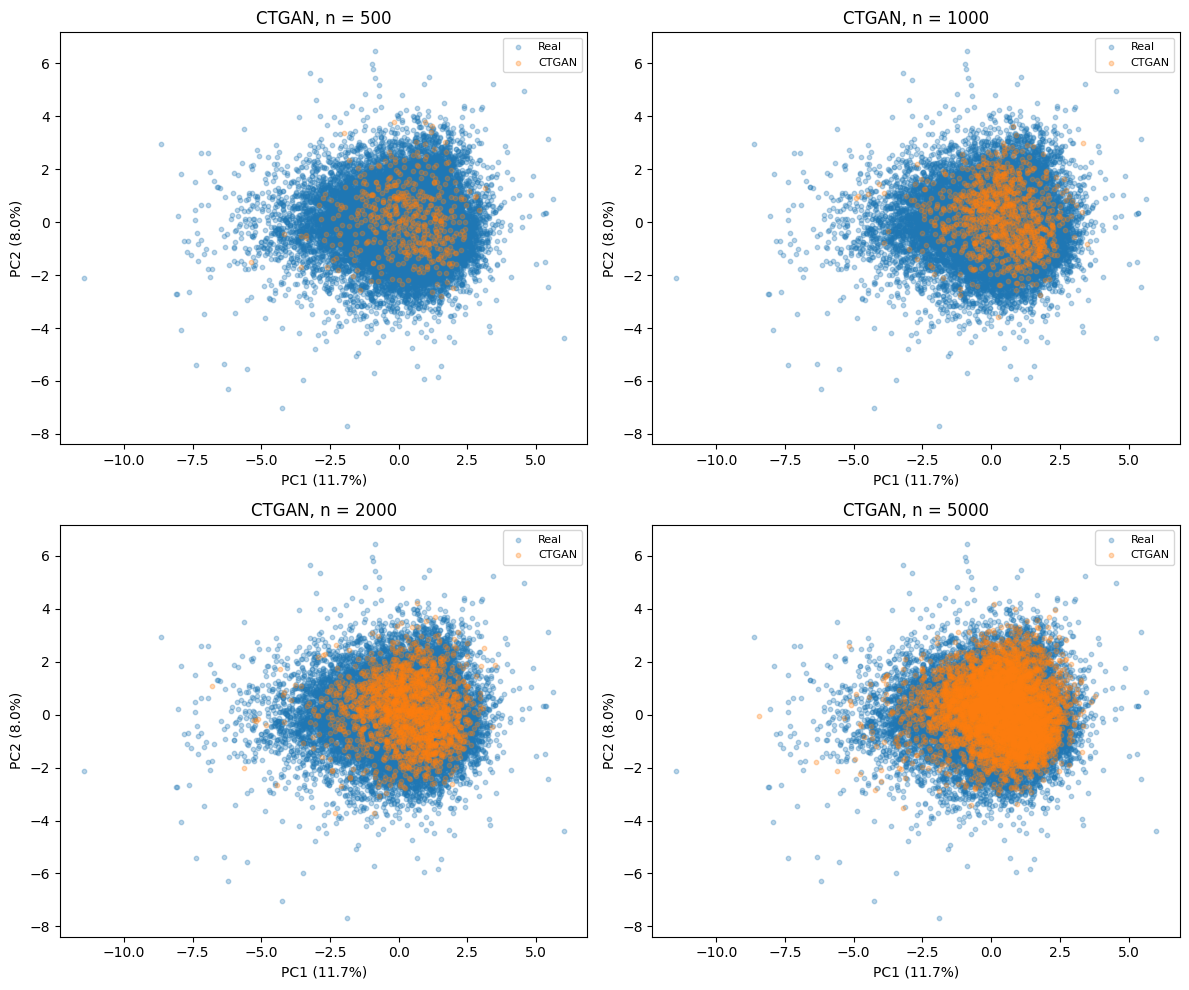

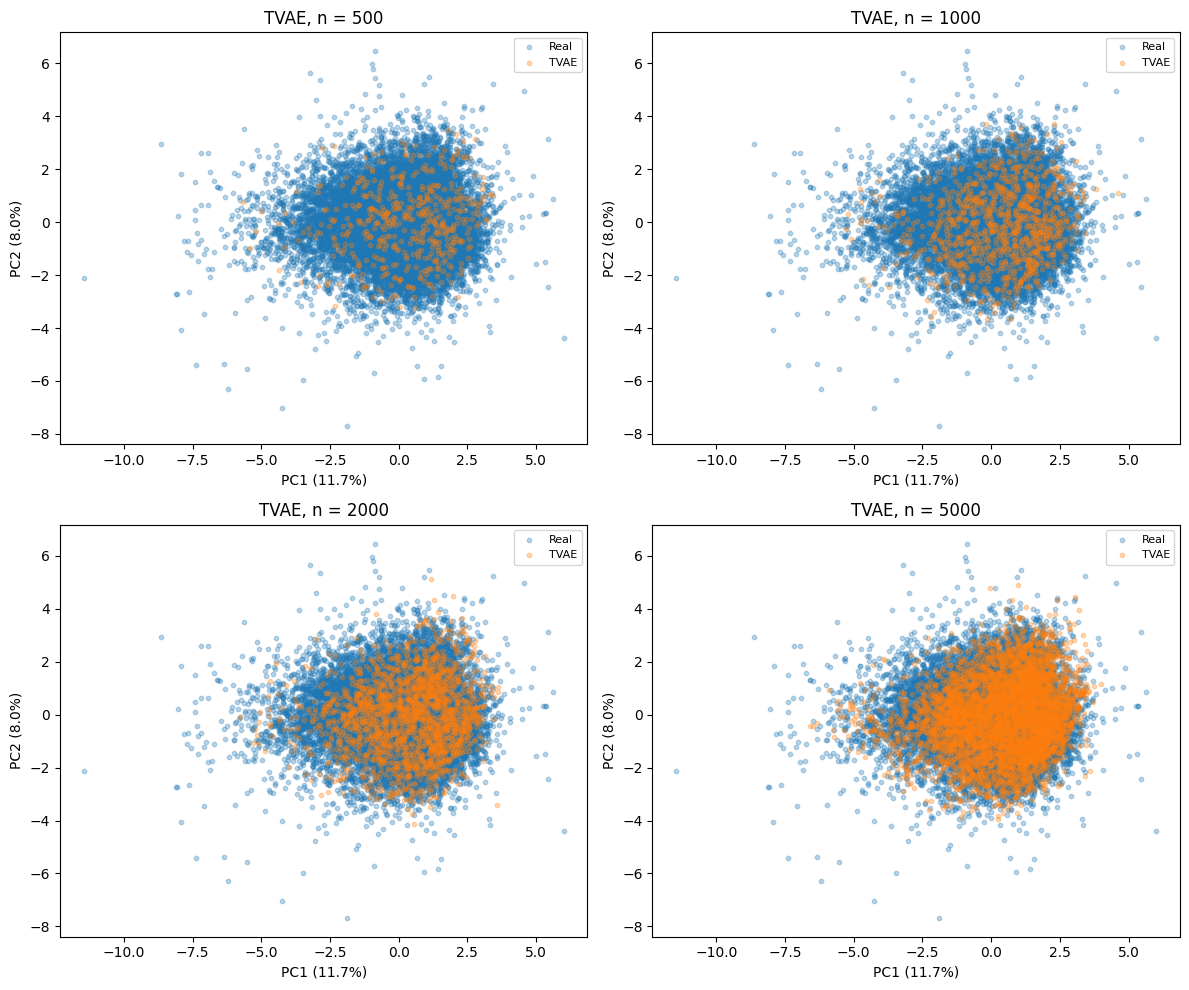

In [73]:
def plot_pca_grid(real_df, synth_dict, model_name, sample_sizes, real_pca, pca, pca_scaler, ncols=2):
    nrows = int(np.ceil(len(sample_sizes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
    axes = np.array(axes).reshape(-1)

    for idx, n in enumerate(sample_sizes):
        synth_scaled = pca_scaler.transform(synth_dict[n])
        synth_pca = pca.transform(synth_scaled)

        ax = axes[idx]
        ax.scatter(real_pca[:, 0], real_pca[:, 1], alpha=0.3, label='Real', s=10)
        ax.scatter(synth_pca[:, 0], synth_pca[:, 1], alpha=0.3, label=model_name, s=10)
        ax.set_title(f'{model_name}, n = {n}')
        ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
        ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
        ax.legend(fontsize=8)

    for j in range(len(sample_sizes), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

pca_scaler = StandardScaler()
real_scaled = pca_scaler.fit_transform(X_bal)

pca = PCA(n_components=2)
real_pca = pca.fit_transform(real_scaled)

for model_name, synth_dict in [('CTGAN', synthetic_ctgan), ('TVAE', synthetic_tvae)]:
    plot_pca_grid(X_bal, synth_dict, model_name, sample_size, real_pca, pca, pca_scaler)

In [ ]:
def normalize(series):
    denom = series.max() - series.min()
    if denom == 0:
        return pd.Series(0.0, index=series.index)
    return (series - series.min()) / denom


spread_df = df_diagnostics.copy()
spread_df['ks_dissimilarity'] = 1 - spread_df['ks_complement']
spread_df['c2st_dissimilarity'] = (spread_df['c2st_auc'] - 0.5).abs() * 2
spread_df['hellinger_dissimilarity'] = spread_df['hellinger_mean']

diss_cols = ['ks_dissimilarity', 'c2st_dissimilarity', 'hellinger_dissimilarity']
for col in diss_cols:
    spread_df[col + '_norm'] = normalize(spread_df[col])

spread_df['spread_score'] = spread_df[[c + '_norm' for c in diss_cols]].mean(axis=1)

selected_configs = pd.DataFrame([
    {'model': 'CTGAN', 'n_samples': 2000, 'role': 'CTGAN - campione piu concentrato/stringente'},
    {'model': 'TVAE', 'n_samples': 2000, 'role': 'TVAE - campione piu sparso'},
    {'model': 'CTGAN', 'n_samples': 1000, 'role': 'CTGAN - campione piu concentrato/stringente'},
    {'model': 'TVAE', 'n_samples': 1000, 'role': 'TVAE - campione piu sparso'}
])

selected_metrics = selected_configs.merge(spread_df, on=['model', 'n_samples'], how='left')
selected_metrics = selected_metrics.sort_values(['model', 'n_samples']).reset_index(drop=True)

print(selected_metrics[[
    'model', 'n_samples', 'role', 'quality_score', 'ks_complement',
    'c2st_auc', 'hellinger_mean', 'spread_score'
]])


In [ ]:
with open('results_bnn.pkl', 'rb') as f:
    results_bnn = pickle.load(f)
with open('results_mc_dropout.pkl', 'rb') as f:
    results_mlp_mc = pickle.load(f)

thr_bnn = {col: v['threshold'] for col, v in results_bnn.items() if isinstance(v, dict) and 'threshold' in v}
thr_mlp_dropout = {col: v['threshold'] for col, v in results_mlp_mc.items() if isinstance(v, dict) and 'threshold' in v}

label_cols = list(thr_bnn.keys())
print('Labels:', label_cols)
print('BNN thresholds:', thr_bnn)
print('MLP-MC thresholds:', thr_mlp_dropout)

In [77]:
def bnn_predict(model, x_tensor, n_samples=100, seed=None):
    if seed is not None:
        set_all_seeds(seed)
    model.eval()
    with torch.no_grad():
        preds = torch.stack([torch.sigmoid(model(x_tensor)) for _ in range(n_samples)])
    prob_mean = preds.mean(0).numpy()
    prob_std = preds.std(0).numpy()
    return prob_mean, prob_std


def mlp_mc_predict(model, x_tensor, n_samples=100, seed=None):
    if seed is not None:
        set_all_seeds(seed)
    model.eval()
    model.drop_enable()
    with torch.no_grad():
        preds = torch.stack([torch.sigmoid(model(x_tensor)) for _ in range(n_samples)])
    prob_mean = preds.mean(0).numpy()
    prob_std = preds.std(0).numpy()
    return prob_mean, prob_std


In [ ]:
def summarize_no_gt(prob_mean, prob_std, thresholds, label_cols):
    eps = 1e-8
    rows = {}
    for i, col in enumerate(label_cols):
        p = prob_mean[:, i]
        thr = thresholds[col]
        pred = (p >= thr).astype(int)
        entropy_i = -p * np.log2(p + eps) - (1 - p) * np.log2(1 - p + eps)

        rows[col] = {
            'mean_prob': p.mean(),
            'uncertainty': prob_std[:, i].mean() * 100,
            'ambiguity': entropy_i.mean(),
            'predicted_positive_rate': pred.mean(),
            'threshold': thr
        }
    return pd.DataFrame(rows).T


synthetic_prob = {}
synthetic_std = {}
synthetic_summary = {}
seed_offset = {'ctgan': 0, 'tvae': 10_000}

for i in sample_size:
    for synth_name, synth_dict in [('ctgan', synthetic_ctgan), ('tvae', synthetic_tvae)]:
        X_synth = synth_dict[i][feature_cols]
        x_synth_t = torch.tensor(scaler.transform(X_synth), dtype=torch.float32)

        prob_bnn, std_bnn = bnn_predict(
            bnn_model,
            x_synth_t,
            n_samples=100,
            seed=GLOBAL_SEED + 30_000 + seed_offset[synth_name] + i,
        )
        prob_mlp, std_mlp = mlp_mc_predict(
            mlp_model,
            x_synth_t,
            n_samples=100,
            seed=GLOBAL_SEED + 40_000 + seed_offset[synth_name] + i,
        )

        synthetic_prob[(i, synth_name, 'bnn')] = prob_bnn
        synthetic_prob[(i, synth_name, 'mlp_mc')] = prob_mlp
        synthetic_std[(i, synth_name, 'bnn')] = std_bnn
        synthetic_std[(i, synth_name, 'mlp_mc')] = std_mlp

        synthetic_summary[(i, synth_name, 'bnn')] = summarize_no_gt(prob_bnn, std_bnn, thr_bnn, label_cols)
        synthetic_summary[(i, synth_name, 'mlp_mc')] = summarize_no_gt(prob_mlp, std_mlp, thr_mlp_dropout, label_cols)

selected_summary = pd.concat({
    (row.model, row.n_samples, pred_model.upper()): synthetic_summary[(row.n_samples, row.model.lower(), pred_model)]
    for _, row in selected_configs.iterrows()
    for pred_model in ['bnn', 'mlp_mc']
}, names=['generator', 'n_samples', 'predictive_model', 'label'])

print(selected_summary[['mean_prob', 'uncertainty', 'ambiguity', 'predicted_positive_rate', 'threshold']])


In [89]:
def build_patient_level_df(prob_mean, prob_std, thresholds, label_cols, model_name, source_name):
    eps = 1e-8
    rows = []
    for i, col in enumerate(label_cols):
        p = prob_mean[:, i]
        std = prob_std[:, i]
        thr = thresholds[col]
        ambiguity = -p * np.log2(p + eps) - (1 - p) * np.log2(1 - p + eps)
        pred = (p >= thr).astype(int)

        df_tmp = pd.DataFrame({
            'model': model_name,
            'source': source_name,
            'patient_id': np.arange(len(p)),
            'label': col,
            'probability': p,
            'uncertainty': std,
            'uncertainty_pct': std * 100,
            'ambiguity': ambiguity,
            'threshold': thr,
            'prediction': pred,
            'distance_from_threshold': np.abs(p - thr)
        })
        rows.append(df_tmp)
    return pd.concat(rows, ignore_index=True)


patient_level_synthetic = {}
for i in sample_size:
    for synth_name in ['ctgan', 'tvae']:
        patient_level_synthetic[(i, synth_name, 'bnn')] = build_patient_level_df(
            synthetic_prob[(i, synth_name, 'bnn')], synthetic_std[(i, synth_name, 'bnn')],
            thr_bnn, label_cols, 'BNN', f'{synth_name}_{i}'
        )
        patient_level_synthetic[(i, synth_name, 'mlp_mc')] = build_patient_level_df(
            synthetic_prob[(i, synth_name, 'mlp_mc')], synthetic_std[(i, synth_name, 'mlp_mc')],
            thr_mlp_dropout, label_cols, 'MC Dropout', f'{synth_name}_{i}'
        )

In [ ]:
selected_patient_configs = [
    ('ctgan', 1000, 'CTGAN 1000'),
    ('ctgan', 2000, 'CTGAN 2000 '),
    ('tvae', 1000, 'TVAE 1000'),
    ('tvae', 2000, 'TVAE 2000'),
]

selected_predictive_models = [
    ('bnn', 'BNN'),
    ('mlp_mc', 'MLP-MC Dropout'),
]

print('Configurazioni patient-level selezionate:')
for synth_name, n, role in selected_patient_configs:
    print(f'- {role}: {synth_name.upper()} con {n} campioni')


In [ ]:
with open('patient_level_bnn.pkl', 'rb') as f:
    df_real_bnn = pickle.load(f)
with open('patient_level_mc_dropout.pkl', 'rb') as f:
    df_real_mlp = pickle.load(f)

if 'distance_from_threshold' not in df_real_bnn.columns:
    df_real_bnn = df_real_bnn.assign(distance_from_threshold=lambda d: (d['probability'] - d['threshold']).abs())
if 'distance_from_threshold' not in df_real_mlp.columns:
    df_real_mlp = df_real_mlp.assign(distance_from_threshold=lambda d: (d['probability'] - d['threshold']).abs())


def overconfidence_check(df_real, df_synth, label_cols):
    rows = []
    for col in label_cols:
        real_g = df_real[df_real['label'] == col]
        synth_g = df_synth[df_synth['label'] == col]
        rows.append({
            'label': col,
            'real_uncertainty_pct': real_g['uncertainty_pct'].mean(),
            'synthetic_uncertainty_pct': synth_g['uncertainty_pct'].mean(),
            'real_ambiguity': real_g['ambiguity'].mean(),
            'synthetic_ambiguity': synth_g['ambiguity'].mean(),
            'real_sharpness': real_g['distance_from_threshold'].mean(),
            'synthetic_sharpness': synth_g['distance_from_threshold'].mean(),
        })
    out = pd.DataFrame(rows).set_index('label')
    out['uncertainty_ratio'] = out['synthetic_uncertainty_pct'] / out['real_uncertainty_pct']
    out['ambiguity_ratio'] = out['synthetic_ambiguity'] / out['real_ambiguity']
    out['sharpness_ratio'] = out['synthetic_sharpness'] / out['real_sharpness']
    return out


calib_summary = pd.concat({
    (model_label, f'{synth_name}_{n}'): overconfidence_check(
        df_real_bnn if model_key == 'bnn' else df_real_mlp,
        patient_level_synthetic[(n, synth_name, model_key)],
        label_cols,
    )
    for synth_name, n, _ in selected_patient_configs
    for model_key, model_label in selected_predictive_models
}, names=['predictive_model', 'synthetic_source'])

print(calib_summary[['uncertainty_ratio', 'ambiguity_ratio', 'sharpness_ratio']])


In [ ]:
def zscore(series):
    std = series.std(ddof=0)
    if std == 0 or pd.isna(std):
        return pd.Series(0.0, index=series.index)
    return (series - series.mean()) / std


common_patient_ids = None
for synth_name, n, _ in selected_patient_configs:
    for model_key, _ in selected_predictive_models:
        ids = set(patient_level_synthetic[(n, synth_name, model_key)]['patient_id'].unique())
        common_patient_ids = ids if common_patient_ids is None else common_patient_ids.intersection(ids)

common_patient_ids = sorted(common_patient_ids)
score_parts = []

for synth_name, n, role in selected_patient_configs:
    for model_key, model_label in selected_predictive_models:
        df_tmp = patient_level_synthetic[(n, synth_name, model_key)]
        df_tmp = df_tmp[df_tmp['patient_id'].isin(common_patient_ids)].copy()
        df_tmp['row_interest'] = (
            zscore(df_tmp['uncertainty_pct'])
            + zscore(df_tmp['ambiguity'])
            + zscore(-df_tmp['distance_from_threshold'])
        )
        score_parts.append(
            df_tmp.groupby('patient_id')['row_interest']
            .mean()
            .rename(f'{synth_name}_{n}_{model_key}_interest')
        )

    df_bnn = patient_level_synthetic[(n, synth_name, 'bnn')]
    df_mlp = patient_level_synthetic[(n, synth_name, 'mlp_mc')]
    merged_tmp = df_bnn.merge(df_mlp, on=['patient_id', 'label'], suffixes=('_bnn', '_mlp'))
    merged_tmp = merged_tmp[merged_tmp['patient_id'].isin(common_patient_ids)].copy()
    merged_tmp['disagreement'] = merged_tmp['prediction_bnn'] != merged_tmp['prediction_mlp']
    merged_tmp['prob_gap'] = (merged_tmp['probability_bnn'] - merged_tmp['probability_mlp']).abs()
    merged_tmp['disagreement_interest'] = merged_tmp['disagreement'].astype(float) + zscore(merged_tmp['prob_gap'])
    score_parts.append(
        merged_tmp.groupby('patient_id')['disagreement_interest']
        .mean()
        .rename(f'{synth_name}_{n}_bnn_vs_mlp_interest')
    )

patient_interest = pd.concat(score_parts, axis=1)
patient_interest['interesting_score'] = patient_interest.mean(axis=1)
top_interesting_patients = (
    patient_interest['interesting_score']
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

selected_patient_id = int(top_interesting_patients.iloc[0]['patient_id'])
print(f'Patient_id selezionato per tutte le 8 tabelle: {selected_patient_id}')
print('\nTop 10 patient_id per interesting_score:')
print(top_interesting_patients)


In [ ]:
def patient_prediction_table(synth_name, n, model_key, patient_id):
    cols = ['probability', 'uncertainty_pct', 'ambiguity', 'threshold', 'distance_from_threshold', 'prediction']
    out = (
        patient_level_synthetic[(n, synth_name, model_key)]
        .loc[lambda d: d['patient_id'] == patient_id, ['label'] + cols]
        .set_index('label')
        .rename(columns={
            'probability': 'prob',
            'uncertainty_pct': 'uncertainty_pct',
            'distance_from_threshold': 'dist_threshold',
        })
    )
    return out


for synth_name, n, role in selected_patient_configs:
    for model_key, model_label in selected_predictive_models:
        display(Markdown(f'### {role} - {model_label} - patient_id {selected_patient_id}'))
        display(patient_prediction_table(synth_name, n, model_key, selected_patient_id))


In [ ]:
def build_model_agreement_df(synth_name, n):
    df_bnn = patient_level_synthetic[(n, synth_name, 'bnn')]
    df_mlp = patient_level_synthetic[(n, synth_name, 'mlp_mc')]
    merged = df_bnn.merge(df_mlp, on=['patient_id', 'label'], suffixes=('_bnn', '_mlp'))
    merged['disagreement'] = merged['prediction_bnn'] != merged['prediction_mlp']
    merged['prob_gap'] = (merged['probability_bnn'] - merged['probability_mlp']).abs()
    return merged


fig, axes = plt.subplots(2, 2, figsize=(12, 11), sharex=True, sharey=True)
axes = axes.flatten()
palette = dict(zip(sorted(label_cols), sns.color_palette('Set2', n_colors=len(label_cols))))

for ax, (synth_name, n, role) in zip(axes, selected_patient_configs):
    merged_plot = build_model_agreement_df(synth_name, n)
    for label, group in merged_plot.groupby('label'):
        ax.scatter(
            group['probability_bnn'],
            group['probability_mlp'],
            s=16, alpha=0.35, color=palette[label], label=label
        )

    disagreement_rate = merged_plot['disagreement'].mean()
    mean_gap = merged_plot['prob_gap'].mean()
    ax.plot([0, 1], [0, 1], color='#d62728', linestyle='--', linewidth=1.3)
    ax.set_title(f'{role}\nDisagreement={disagreement_rate:.1%}, mean gap={mean_gap:.3f}')
    ax.set_xlabel('BNN probability')
    ax.set_ylabel('MLP-MC probability')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(label_cols), frameon=False)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [100]:
labels_order = list(label_cols)
x = np.arange(len(labels_order))
bar_width = 0.36
model_styles = {
    'bnn': {'label': 'BNN', 'color': '#4C78A8', 'threshold_color': '#24496B'},
    'mlp_mc': {'label': 'MLP-MC Dropout', 'color': '#F58518', 'threshold_color': '#8F4A05'},
}

In [101]:
def get_patient_mc_raw_samples(synth_name, n, model_key, patient_id, n_samples=100):
    """Re-runs MC inference for a single patient only, keeping the raw samples."""
    synth_df = synthetic_ctgan[n] if synth_name == 'ctgan' else synthetic_tvae[n]
    x_row = synth_df[feature_cols].iloc[[patient_id]]
    x_tensor = torch.tensor(scaler.transform(x_row), dtype=torch.float32)

    seed_offset_key = seed_offset[synth_name]
    if model_key == 'bnn':
        seed = GLOBAL_SEED + 30_000 + seed_offset_key + n
        set_all_seeds(seed)
        bnn_model.eval()
        with torch.no_grad():
            preds = torch.stack([torch.sigmoid(bnn_model(x_tensor)) for _ in range(n_samples)])
    else:
        seed = GLOBAL_SEED + 40_000 + seed_offset_key + n
        set_all_seeds(seed)
        mlp_model.eval()
        mlp_model.drop_enable()
        with torch.no_grad():
            preds = torch.stack([torch.sigmoid(mlp_model(x_tensor)) for _ in range(n_samples)])

    return preds.squeeze(1).numpy()  # shape (n_samples, n_labels)

In [ ]:
model_styles = {
    'bnn': {'label': 'BNN', 'color': '#4C78A8'},
    'mlp_mc': {'label': 'MLP Dropout', 'color': '#F58518'},
}

fig, axes = plt.subplots(
    len(selected_patient_configs), len(labels_order),
    figsize=(4.0 * len(labels_order), 2.8 * len(selected_patient_configs)),
    sharex=True, sharey=False,
)

for row_idx, (synth_name, n, role) in enumerate(selected_patient_configs):
    for col_idx, label in enumerate(labels_order):
        ax = axes[row_idx, col_idx]

        kde_rows, patient_rows = [], []
        for model_key, style in model_styles.items():
            df_model = patient_level_synthetic[(n, synth_name, model_key)]
            label_df = df_model[df_model['label'] == label].copy()
            label_df['predictive_model'] = style['label']
            kde_rows.append(label_df)
            patient_value = label_df.loc[label_df['patient_id'] == selected_patient_id, 'probability'].iloc[0]
            threshold_value = label_df['threshold'].iloc[0]
            patient_rows.append((model_key, style, patient_value, threshold_value))

        kde_df = pd.concat(kde_rows, ignore_index=True)

        thr_vals = sorted(v for *_, v in patient_rows)
        ax.axvspan(thr_vals[0], thr_vals[1], color='grey', alpha=0.08, zorder=0)

        for model_key, style in model_styles.items():
            model_df = kde_df[kde_df['predictive_model'] == style['label']]
            if model_df['probability'].nunique() > 1:
                sns.kdeplot(data=model_df, x='probability', ax=ax, color=style['color'],
                            linewidth=1.6, fill=True, alpha=0.12, clip=(0, 1), warn_singular=False)
            else:
                ax.axvline(model_df['probability'].iloc[0], color=style['color'], linewidth=1.6)

        for model_key, style, patient_value, threshold_value in patient_rows:
            ax.axvline(patient_value, color=style['color'], linewidth=2.0)
            ax.axvline(threshold_value, color=style['color'], linestyle=':', linewidth=1.2, alpha=0.7)

        ax.set_yticks([])
        if row_idx == 0:
            ax.set_title(label, fontsize=11)
        ax.set_ylabel(role if col_idx == 0 else '', fontsize=10)
        ax.set_xlim(0, 1)
        ax.set_xlabel('')
        ax.spines[['top', 'right', 'left']].set_visible(False)
        ax.grid(axis='x', alpha=0.15)

fig.supxlabel('Predicted probability', y=0.01)
legend_handles = [
    plt.Line2D([0], [0], color=model_styles['bnn']['color'], lw=2, label='BNN (density / patient value)'),
    plt.Line2D([0], [0], color=model_styles['mlp_mc']['color'], lw=2, label='MLP Dropout (density / patient value)'),
    plt.Line2D([0], [0], color='grey', lw=1.2, linestyle=':', label='Model threshold'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()

In [ ]:
model_styles = {
    'bnn': {'label': 'BNN', 'color': '#4C78A8'},
    'mlp_mc': {'label': 'MLP Dropout', 'color': '#F58518'},
}

fig, axes = plt.subplots(
    len(selected_patient_configs), len(labels_order),
    figsize=(4.0 * len(labels_order), 2.8 * len(selected_patient_configs)),
    sharex=True, sharey=True,
)

for row_idx, (synth_name, n, role) in enumerate(selected_patient_configs):
    for col_idx, label in enumerate(labels_order):
        ax = axes[row_idx, col_idx]
        label_idx = labels_order.index(label)

        for y_pos, (model_key, style) in zip([1, 0], model_styles.items()):
            samples = get_patient_mc_raw_samples(synth_name, n, model_key, selected_patient_id)[:, label_idx]
            tbl = patient_prediction_table(synth_name, n, model_key, selected_patient_id)
            thr = tbl.loc[label, 'threshold']
            mean_val = samples.mean()

            parts = ax.violinplot(samples, positions=[y_pos], vert=False,
                                    widths=0.7, showextrema=False)
            for pc in parts['bodies']:
                pc.set_facecolor(style['color'])
                pc.set_alpha(0.35)
            ax.scatter(mean_val, y_pos, color=style['color'], s=45, zorder=3, edgecolor='white')
            ax.plot([thr, thr], [y_pos - 0.35, y_pos + 0.35],
                    color=style['color'], linestyle=':', linewidth=1.6, zorder=2)

        ax.set_yticks([0, 1])
        ax.set_yticklabels(['MLP Dropout', 'BNN'] if col_idx == 0 else ['', ''], fontsize=8)
        if row_idx == 0:
            ax.set_title(label, fontsize=11)
        if col_idx == 0:
            ax.text(-0.28, 0.5, role, transform=ax.transAxes, ha='center', va='center',
                     rotation=90, fontsize=9)
        ax.set_xlim(0, 1)
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='x', alpha=0.15)

legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_styles['bnn']['color'], markersize=8, label='BNN mean'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_styles['mlp_mc']['color'], markersize=8, label='MLP Dropout mean'),
    plt.Line2D([0], [0], color='grey', lw=1.4, linestyle=':', label='Threshold'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.supxlabel('Predicted probability (100 MC samples)', y=0.01)
plt.tight_layout(rect=[0.03, 0.02, 1, 0.95])
plt.show()

In [ ]:
feature_profiles = []
for synth_name, n, role in selected_patient_configs:
    synth_df = synthetic_ctgan[n] if synth_name == 'ctgan' else synthetic_tvae[n]
    profile = synth_df.loc[[selected_patient_id]].copy()
    profile.insert(0, 'source', f'{synth_name}_{n}')
    profile.insert(1, 'role', role)
    feature_profiles.append(profile)

selected_patient_feature_profiles = pd.concat(feature_profiles, ignore_index=True)
display(selected_patient_feature_profiles)


In [ ]:
import pickle

stress_test_bundle = {
    "GLOBAL_SEED": GLOBAL_SEED,
    "feature_cols": feature_cols,
    "label_cols": label_cols,
    "thr_bnn": thr_bnn,
    "thr_mlp_dropout": thr_mlp_dropout,
    "seed_offset": seed_offset,
    "sample_size": sample_size,
    "scaler": scaler,
    "spread_df": spread_df,
    "synthetic_ctgan": synthetic_ctgan,
    "synthetic_tvae": synthetic_tvae,
    "data": data,  # = X_bal, real training data (needed for REF_STD/REF_RANGE)
    # optional but convenient for the Chapter 5 case study (avoids recomputing it):
    "patient_level_synthetic": patient_level_synthetic,
    "top_interesting_patients": top_interesting_patients,  # the 10 patients of Chapter 4
    "selected_patient_id": selected_patient_id,
}

with open("stress_test_bundle.pkl", "wb") as f:
    pickle.dump(stress_test_bundle, f)

print("Salvato stress_test_bundle.pkl con le chiavi:", list(stress_test_bundle.keys()))